<a href="https://colab.research.google.com/github/olopez27CL/Lab01_EDA_Lopez_Omar/blob/main/Laboratorio_2_8_FIFA19.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import kagglehub
from pathlib import Path

# Descargar el dataset de FIFA 19
ruta_fifa = kagglehub.dataset_download(
    "alirezahasannejad/fifa19"
)

# Mostrar los archivos disponibles
print("Archivos disponibles:")
for archivo in sorted(Path(ruta_fifa).rglob("*")):
    if archivo.is_file():
        print(archivo.relative_to(ruta_fifa))

Using Colab cache for faster access to the 'fifa19' dataset.
Archivos disponibles:
Revised-FIFA19.csv


In [2]:
import pandas as pd
from pathlib import Path

# Cargar el archivo descargado
df_fifa = pd.read_csv(Path(ruta_fifa) / "Revised-FIFA19.csv")

print("Filas y columnas:", df_fifa.shape)
display(df_fifa.head())

print("\nInformación del dataset:")
df_fifa.info()

print("\nColumnas disponibles:")
print(df_fifa.columns.tolist())

print("\nColumnas con valores nulos:")
nulos_fifa = df_fifa.isna().sum()
print(nulos_fifa[nulos_fifa > 0])

print("\nFilas duplicadas:", df_fifa.duplicated().sum())

Filas y columnas: (18207, 90)


,Unnamed: 0.1,Unnamed: 0,ID,Name,Age,Photo,Nationality,Flag,Overall,Potential,...,Composure,Marking,StandingTackle,SlidingTackle,GKDiving,GKHandling,GKKicking,GKPositioning,GKReflexes,Release Clause
0,0,0,158023,L. Messi,31,https://cdn.sofifa.org/players/4/19/158023.png,Argentina,https://cdn.sofifa.org/flags/52.png,94,94,...,96.0,33.0,28.0,26.0,6.0,11.0,15.0,14.0,8.0,€226.5M
1,1,1,20801,Cristiano Ronaldo,33,https://cdn.sofifa.org/players/4/19/20801.png,Portugal,https://cdn.sofifa.org/flags/38.png,94,94,...,95.0,28.0,31.0,23.0,7.0,11.0,15.0,14.0,11.0,€127.1M
2,2,2,190871,Neymar Jr,26,https://cdn.sofifa.org/players/4/19/190871.png,Brazil,https://cdn.sofifa.org/flags/54.png,92,93,...,94.0,27.0,24.0,33.0,9.0,9.0,15.0,15.0,11.0,€228.1M
3,3,3,193080,De Gea,27,https://cdn.sofifa.org/players/4/19/193080.png,Spain,https://cdn.sofifa.org/flags/45.png,91,93,...,68.0,15.0,21.0,13.0,90.0,85.0,87.0,88.0,94.0,€138.6M
4,4,4,192985,K. De Bruyne,27,https://cdn.sofifa.org/players/4/19/192985.png,Belgium,https://cdn.sofifa.org/flags/7.png,91,92,...,88.0,68.0,58.0,51.0,15.0,13.0,5.0,10.0,13.0,€196.4M



Información del dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18207 entries, 0 to 18206
Data columns (total 90 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Unnamed: 0.1              18207 non-null  int64  
 1   Unnamed: 0                18207 non-null  int64  
 2   ID                        18207 non-null  int64  
 3   Name                      18207 non-null  object 
 4   Age                       18207 non-null  int64  
 5   Photo                     18207 non-null  object 
 6   Nationality               18207 non-null  object 
 7   Flag                      18207 non-null  object 
 8   Overall                   18207 non-null  int64  
 9   Potential                 18207 non-null  int64  
 10  Club                      17966 non-null  object 
 11  Club Logo                 18207 non-null  object 
 12  Value                     17955 non-null  float64
 13  Wage                      18207 non

In [3]:
# Quitar los índices exportados y conservar el original
columnas_indice = [
    columna for columna in df_fifa.columns
    if columna.startswith("Unnamed:")
]

fifa_limpio = df_fifa.drop(columns=columnas_indice).copy()

print("Dimensiones después de quitar índices:", fifa_limpio.shape)

# Revisar objetivo y posición
print("\nResumen de Overall:")
display(fifa_limpio["Overall"].describe())

print("\nJugadores por posición:")
print(fifa_limpio["Position"].value_counts(dropna=False))

# Separar antes de seleccionar predictores por correlación
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

fifa_train, fifa_test = train_test_split(
    fifa_limpio,
    test_size=0.20,
    random_state=RANDOM_STATE
)

print("\nFilas de entrenamiento:", len(fifa_train))
print("Filas de prueba:", len(fifa_test))

Dimensiones después de quitar índices: (18207, 88)

Resumen de Overall:


,Overall
count,18207.000000
mean,66.238699
std,6.908930
min,46.000000
25%,62.000000
50%,66.000000
75%,71.000000
max,94.000000



Jugadores por posición:
Position
ST     2152
GK     2025
CB     1778
CM     1394
LB     1322
RB     1291
RM     1124
LM     1095
CAM     958
CDM     948
RCB     662
LCB     648
LCM     395
RCM     391
LW      381
RW      370
RDM     248
LDM     243
LS      207
RS      203
RWB      87
LWB      78
CF       74
NaN      60
LAM      21
RAM      21
RF       16
LF       15
Name: count, dtype: int64

Filas de entrenamiento: 14565
Filas de prueba: 3642


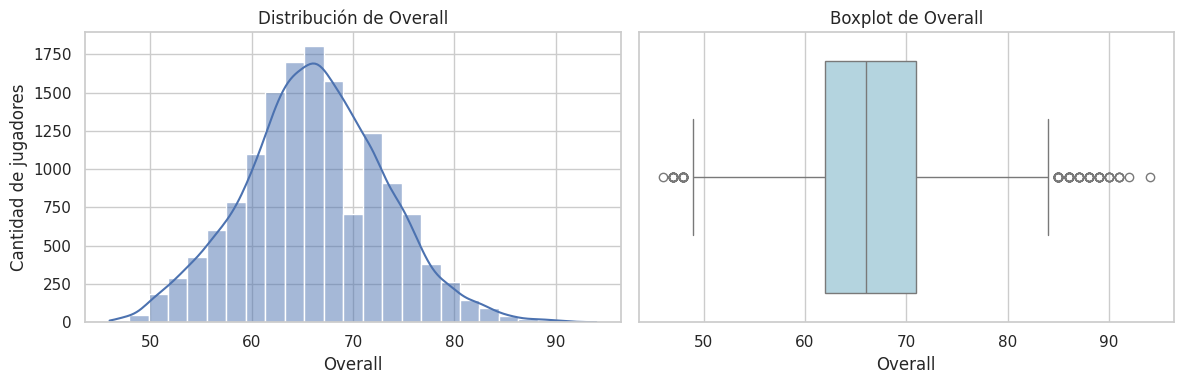

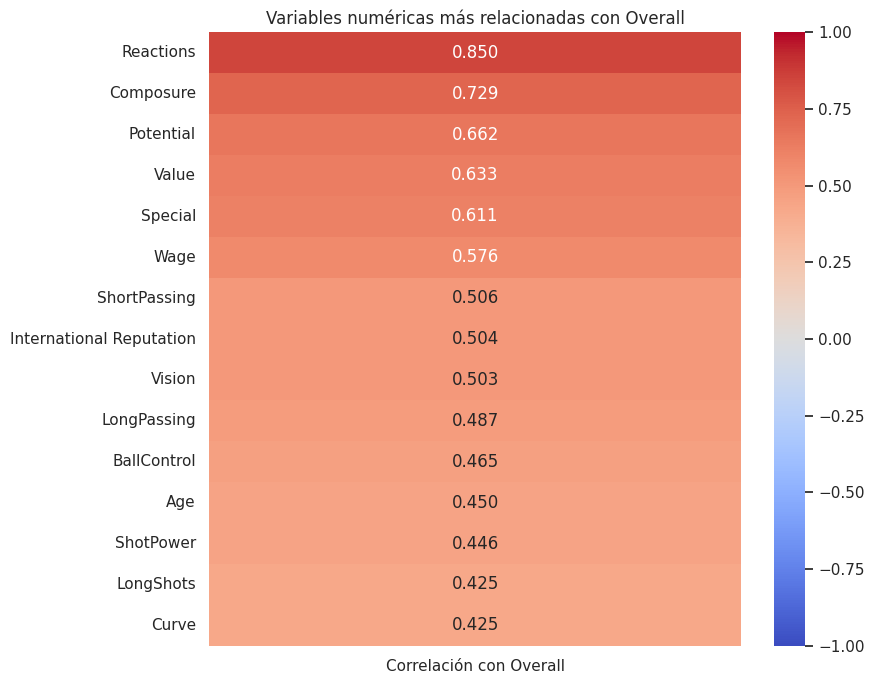

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Distribución y boxplot de la variable objetivo
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(
    data=fifa_train, x="Overall",
    bins=25, kde=True, ax=axes[0]
)
axes[0].set_title("Distribución de Overall")
axes[0].set_ylabel("Cantidad de jugadores")

sns.boxplot(
    data=fifa_train, x="Overall",
    color="lightblue", ax=axes[1]
)
axes[1].set_title("Boxplot de Overall")

plt.tight_layout()
plt.show()

# Correlaciones numéricas, excluyendo identificadores
numericas_fifa = fifa_train.select_dtypes(include="number").drop(
    columns=["ID", "Jersey Number"],
    errors="ignore"
)

correlacion_overall = (
    numericas_fifa.corr()["Overall"]
    .drop("Overall")
    .dropna()
)

# Mostrar las 15 relaciones más fuertes en valor absoluto
orden = correlacion_overall.abs().sort_values(
    ascending=False
).head(15).index

top_correlaciones = correlacion_overall.loc[orden]

plt.figure(figsize=(9, 7))
sns.heatmap(
    top_correlaciones.to_frame("Correlación con Overall"),
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)
plt.title("Variables numéricas más relacionadas con Overall")
plt.tight_layout()
plt.show()

Correlación con Overall:


,Correlación
Reactions,0.850109
Composure,0.728750
ShortPassing,0.506312
Vision,0.503023
LongPassing,0.487446
BallControl,0.464928
Age,0.450299
ShotPower,0.445878


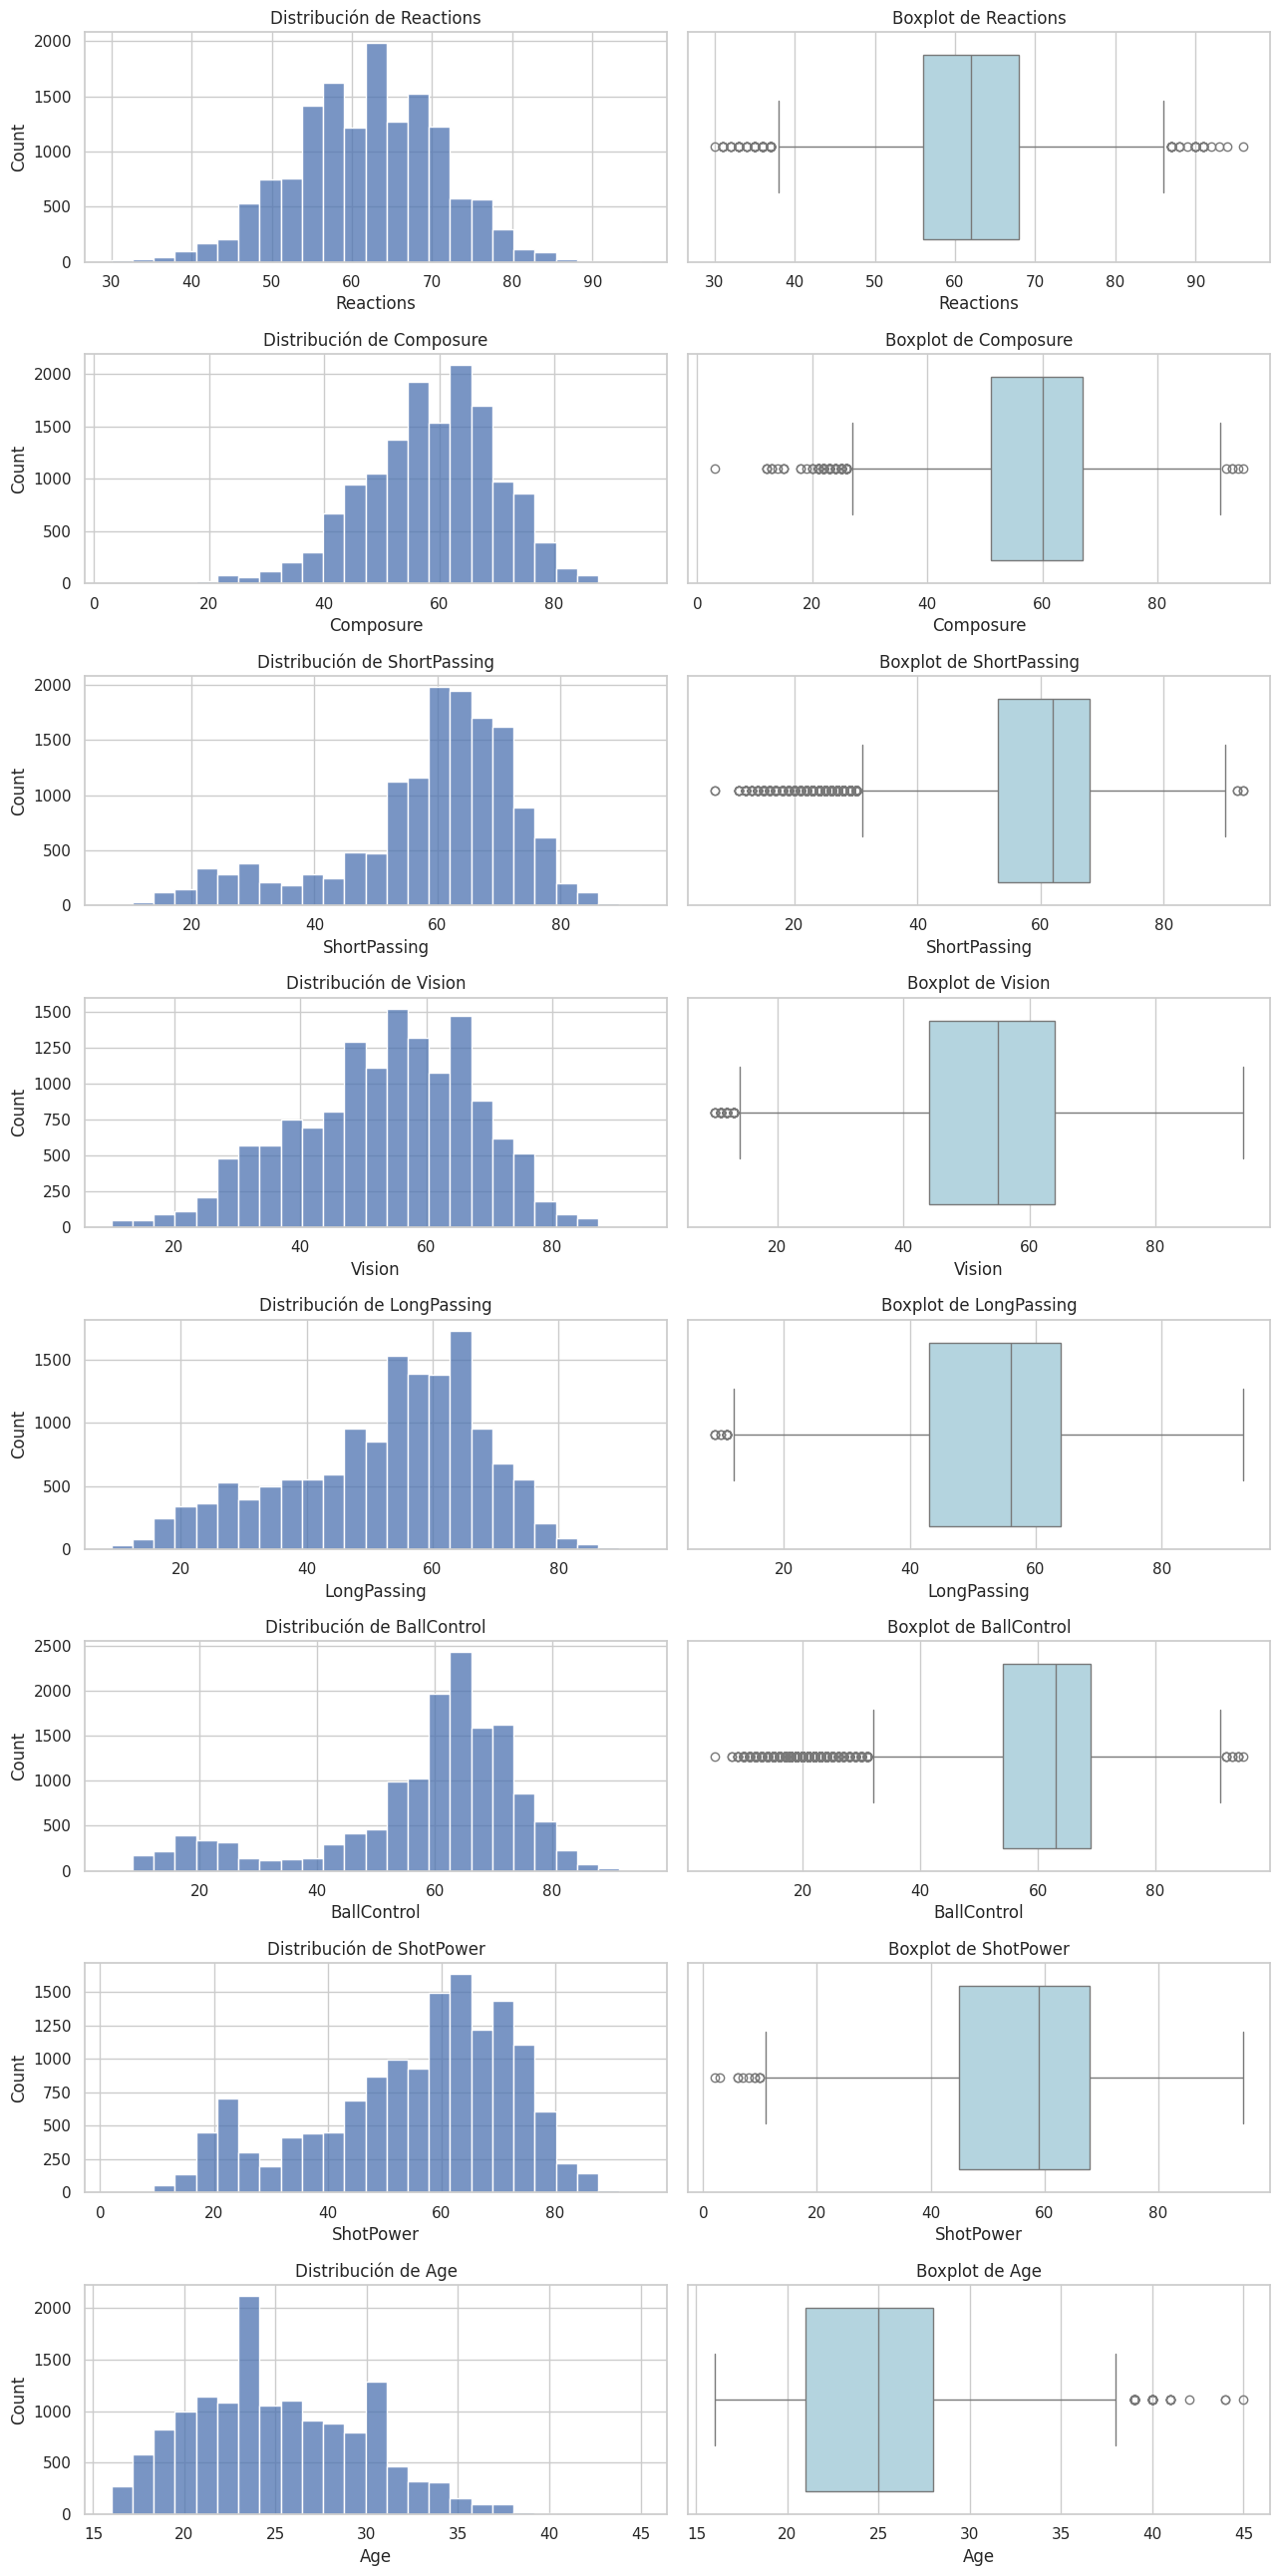


Valores nulos en las candidatas:
Reactions       34
Composure       34
ShortPassing    34
Vision          34
LongPassing     34
BallControl     34
ShotPower       34
Age              0
dtype: int64


In [5]:
candidatas_fifa = [
    "Reactions",
    "Composure",
    "ShortPassing",
    "Vision",
    "LongPassing",
    "BallControl",
    "ShotPower",
    "Age"
]

# Correlación de las candidatas con Overall
print("Correlación con Overall:")
display(
    fifa_train[candidatas_fifa + ["Overall"]]
    .corr()["Overall"]
    .drop("Overall")
    .sort_values(ascending=False)
    .to_frame("Correlación")
)

# Histogramas y boxplots de cada candidata
fig, axes = plt.subplots(8, 2, figsize=(13, 26))

for i, variable in enumerate(candidatas_fifa):
    sns.histplot(
        data=fifa_train, x=variable,
        bins=25, ax=axes[i, 0]
    )
    axes[i, 0].set_title(f"Distribución de {variable}")

    sns.boxplot(
        data=fifa_train, x=variable,
        color="lightblue", ax=axes[i, 1]
    )
    axes[i, 1].set_title(f"Boxplot de {variable}")

plt.tight_layout()
plt.show()

print("\nValores nulos en las candidatas:")
print(fifa_train[candidatas_fifa].isna().sum())

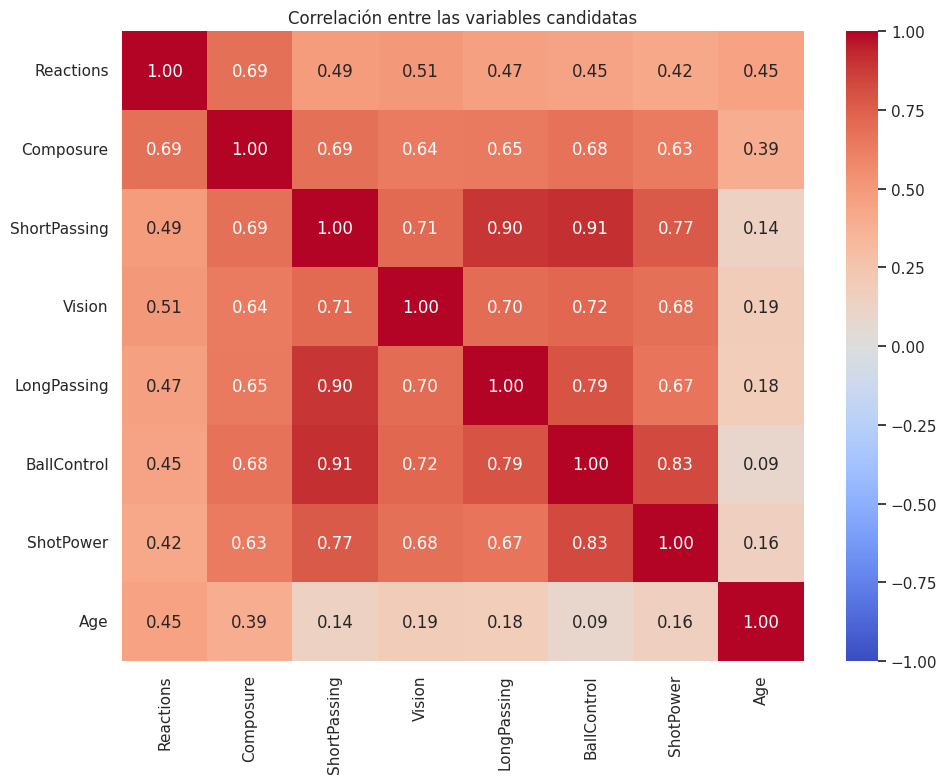

,Variable,VIF
2,ShortPassing,11.751
5,BallControl,8.362
4,LongPassing,5.567
6,ShotPower,3.466
1,Composure,3.113
3,Vision,2.582
0,Reactions,2.121
7,Age,1.392


In [6]:
from sklearn.impute import SimpleImputer
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Calcular las medianas únicamente con entrenamiento
imputador_fifa = SimpleImputer(strategy="median")

X_train_candidatas = pd.DataFrame(
    imputador_fifa.fit_transform(fifa_train[candidatas_fifa]),
    columns=candidatas_fifa,
    index=fifa_train.index
)

# Correlación entre predictores
plt.figure(figsize=(10, 8))
sns.heatmap(
    X_train_candidatas.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)
plt.title("Correlación entre las variables candidatas")
plt.tight_layout()
plt.show()

# Incluir intercepto para calcular correctamente el VIF
X_con_constante = sm.add_constant(X_train_candidatas)

tabla_vif = pd.DataFrame({
    "Variable": candidatas_fifa,
    "VIF": [
        variance_inflation_factor(
            X_con_constante.to_numpy(),
            X_con_constante.columns.get_loc(variable)
        )
        for variable in candidatas_fifa
    ]
}).sort_values("VIF", ascending=False)

display(tabla_vif.round(3))

In [7]:
# Retirar la candidata con mayor VIF
predictoras_fifa = [
    variable for variable in candidatas_fifa
    if variable != "ShortPassing"
]

X_train_fifa = X_train_candidatas[predictoras_fifa].copy()

# Recalcular VIF con las siete variables restantes
X_constante_reducido = sm.add_constant(X_train_fifa)

vif_reducido = pd.DataFrame({
    "Variable": predictoras_fifa,
    "VIF": [
        variance_inflation_factor(
            X_constante_reducido.to_numpy(),
            X_constante_reducido.columns.get_loc(variable)
        )
        for variable in predictoras_fifa
    ]
}).sort_values("VIF", ascending=False)

display(vif_reducido.round(3))

,Variable,VIF
4,BallControl,5.254
5,ShotPower,3.457
1,Composure,3.109
3,LongPassing,3.044
2,Vision,2.573
0,Reactions,2.104
6,Age,1.388


In [8]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

# Completar los nulos de prueba usando las medianas de entrenamiento
X_test_candidatas = pd.DataFrame(
    imputador_fifa.transform(fifa_test[candidatas_fifa]),
    columns=candidatas_fifa,
    index=fifa_test.index
)

X_test_fifa = X_test_candidatas[predictoras_fifa].copy()

y_train_fifa = fifa_train["Overall"]
y_test_fifa = fifa_test["Overall"]

# Entrenar únicamente con entrenamiento
modelo_fifa = LinearRegression()
modelo_fifa.fit(X_train_fifa, y_train_fifa)

pred_train_fifa = modelo_fifa.predict(X_train_fifa)
pred_test_fifa = modelo_fifa.predict(X_test_fifa)

# Comparar métricas en ambos conjuntos
resultados_fifa = []

for nombre, reales, predichos in [
    ("Entrenamiento", y_train_fifa, pred_train_fifa),
    ("Prueba", y_test_fifa, pred_test_fifa)
]:
    resultados_fifa.append({
        "Conjunto": nombre,
        "R²": r2_score(reales, predichos),
        "MAE": mean_absolute_error(reales, predichos),
        "RMSE": np.sqrt(mean_squared_error(reales, predichos))
    })

display(pd.DataFrame(resultados_fifa).round(4))

# Mostrar coeficientes
coeficientes_fifa = pd.DataFrame({
    "Variable": predictoras_fifa,
    "Coeficiente": modelo_fifa.coef_
})

print("\nCoeficientes del modelo:")
display(coeficientes_fifa.round(4))

print("Intercepto:", round(modelo_fifa.intercept_, 4))

,Conjunto,R²,MAE,RMSE
0,Entrenamiento,0.7649,2.6516,3.3605
1,Prueba,0.7628,2.6033,3.3213



Coeficientes del modelo:


,Variable,Coeficiente
0,Reactions,0.4946
1,Composure,0.1659
2,Vision,-0.0019
3,LongPassing,0.0137
4,BallControl,-0.0185
5,ShotPower,0.0046
6,Age,0.0722


Intercepto: 24.3019


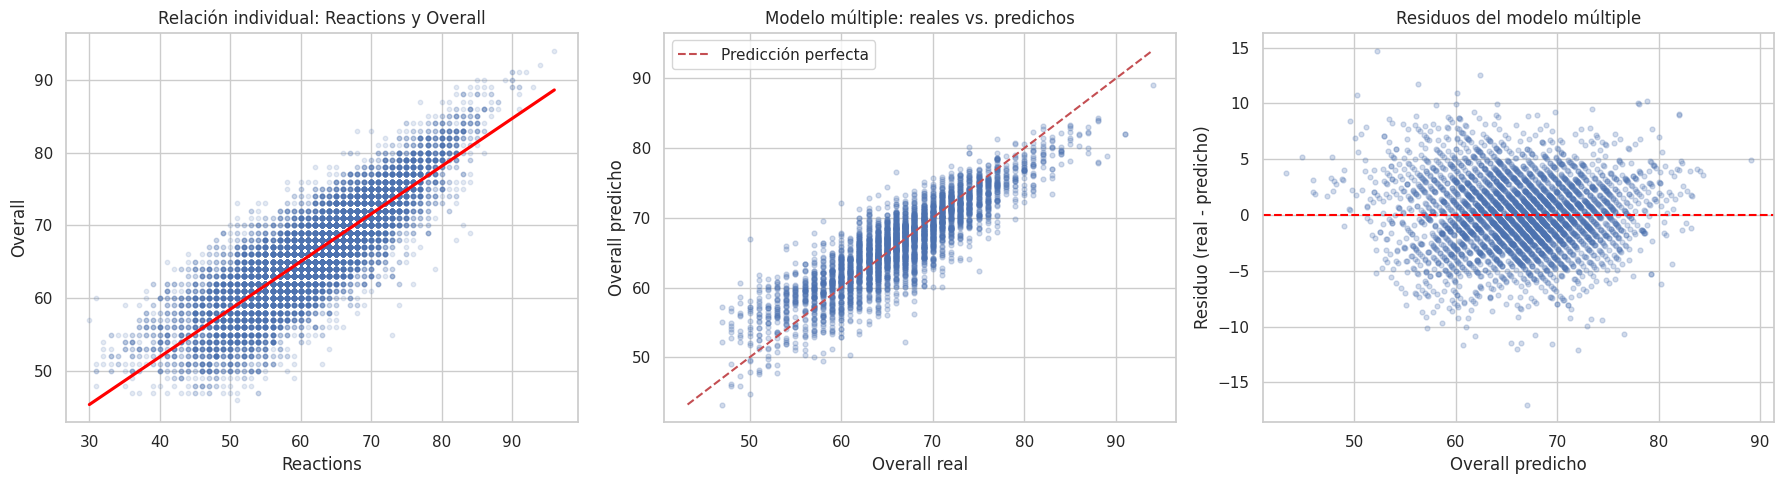

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Relación individual con el predictor más correlacionado
sns.regplot(
    data=fifa_train,
    x="Reactions",
    y="Overall",
    ci=None,
    scatter_kws={"alpha": 0.15, "s": 10},
    line_kws={"color": "red"},
    ax=axes[0]
)
axes[0].set_title("Relación individual: Reactions y Overall")

# Valores reales frente a predicciones del modelo múltiple
axes[1].scatter(
    y_test_fifa, pred_test_fifa,
    alpha=0.25, s=12
)

limite_min = min(y_test_fifa.min(), pred_test_fifa.min())
limite_max = max(y_test_fifa.max(), pred_test_fifa.max())

axes[1].plot(
    [limite_min, limite_max],
    [limite_min, limite_max],
    "r--",
    label="Predicción perfecta"
)
axes[1].set_xlabel("Overall real")
axes[1].set_ylabel("Overall predicho")
axes[1].set_title("Modelo múltiple: reales vs. predichos")
axes[1].legend()

# Residuos de prueba
residuos_fifa = y_test_fifa - pred_test_fifa

axes[2].scatter(
    pred_test_fifa, residuos_fifa,
    alpha=0.25, s=12
)
axes[2].axhline(0, color="red", linestyle="--")
axes[2].set_xlabel("Overall predicho")
axes[2].set_ylabel("Residuo (real - predicho)")
axes[2].set_title("Residuos del modelo múltiple")

plt.tight_layout()
plt.show()

,Grupo,Jugadores,R²,MAE,RMSE,Residuo promedio
0,Jugadores de campo,3205,0.7794,2.4675,3.1371,-0.1717
1,Porteros,422,0.6655,3.5721,4.4471,1.8289
2,Sin posición,15,-2.8118,4.3620,4.3831,-4.3620


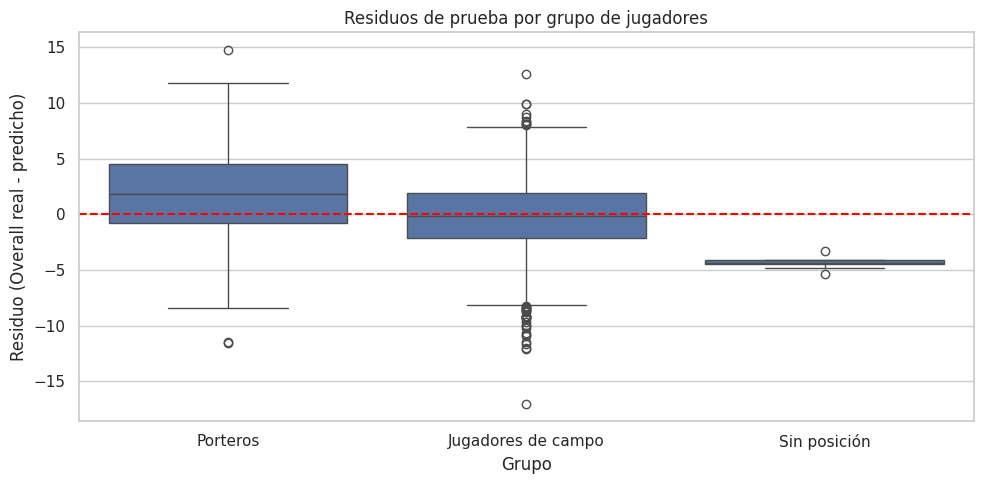

In [10]:
# Reunir resultados de prueba, conservando sus índices
evaluacion_fifa = fifa_test[["Overall", "Position"]].copy()
evaluacion_fifa["Prediccion"] = pred_test_fifa
evaluacion_fifa["Residuo"] = (
    evaluacion_fifa["Overall"] - evaluacion_fifa["Prediccion"]
)

# Definir grupos sin confundir posiciones faltantes con jugadores de campo
evaluacion_fifa["Grupo"] = np.where(
    evaluacion_fifa["Position"].isna(),
    "Sin posición",
    np.where(
        evaluacion_fifa["Position"].eq("GK"),
        "Porteros",
        "Jugadores de campo"
    )
)

# Métricas por grupo
resultados_grupos = []

for grupo, datos in evaluacion_fifa.groupby("Grupo"):
    resultados_grupos.append({
        "Grupo": grupo,
        "Jugadores": len(datos),
        "R²": (
            r2_score(datos["Overall"], datos["Prediccion"])
            if len(datos) >= 2 and datos["Overall"].nunique() > 1
            else np.nan
        ),
        "MAE": mean_absolute_error(
            datos["Overall"], datos["Prediccion"]
        ),
        "RMSE": np.sqrt(mean_squared_error(
            datos["Overall"], datos["Prediccion"]
        )),
        "Residuo promedio": datos["Residuo"].mean()
    })

tabla_grupos_fifa = pd.DataFrame(resultados_grupos)
display(tabla_grupos_fifa.round(4))

# Comparar distribución de residuos
plt.figure(figsize=(10, 5))
sns.boxplot(
    data=evaluacion_fifa,
    x="Grupo",
    y="Residuo"
)
plt.axhline(0, color="red", linestyle="--")
plt.title("Residuos de prueba por grupo de jugadores")
plt.xlabel("Grupo")
plt.ylabel("Residuo (Overall real - predicho)")
plt.tight_layout()
plt.show()

### Selección de variables y prevención de fuga de datos

El objetivo fue estimar Overall suponiendo que conocemos previamente las habilidades individuales y la edad del jugador.

Se revisaron ocho variables candidatas: Reactions, Composure, ShortPassing, Vision, LongPassing, BallControl, ShotPower y Age. Reactions y Composure presentaron las correlaciones más altas con Overall entre estas candidatas.

Se decidió excluir Potential, Value, Wage e International Reputation como medida preventiva, porque podrían incorporar información relacionada con la valoración general o el reconocimiento del jugador. Esto no demuestra que exista fuga, pero evita depender de variables cuya disponibilidad previa no está clara. También se excluyó Special por ser una medida agregada, y los identificadores porque no representan habilidades.

Los valores faltantes se completaron con las medianas calculadas únicamente en entrenamiento. El conjunto de prueba se reservó para evaluar el modelo.

### Revisión de multicolinealidad

ShortPassing presentó un VIF de 11,751 y una correlación muy alta con BallControl y LongPassing. Por eso se retiró y se volvió a calcular el VIF.

Después de este cambio, BallControl quedó con un VIF de 5,254 y las demás variables por debajo de 5. Se conservaron las siete variables restantes, reconociendo que todavía existe cierta información compartida.

### Resultados del modelo

El modelo obtuvo un R² de 0,7649 en entrenamiento y de 0,7628 en prueba. Los resultados fueron similares, por lo que no se observa una señal clara de sobreajuste en esta partición.

En prueba, el MAE fue de aproximadamente 2,60 puntos de Overall y el RMSE fue de 3,32 puntos. Esto indica que el modelo sigue la tendencia general, aunque algunas predicciones presentan errores mayores.

Manteniendo las demás variables constantes, un punto adicional en Reactions se asocia con un aumento estimado de 0,4946 puntos de Overall. En Composure, un punto adicional se asocia con 0,1659 puntos más. En Age, un año adicional se asocia con 0,0722 puntos más.

Estas relaciones describen el modelo y no demuestran que aumentar una característica cause directamente un cambio en Overall.

### Comparación entre grupos

El modelo funcionó mejor para los jugadores de campo, con un MAE de 2,47 puntos, que para los porteros, cuyo MAE fue de 3,57 puntos.

En los porteros, el residuo promedio fue positivo, de aproximadamente 1,83 puntos. Esto indica que el modelo tiende a subestimar su valoración. Una posible explicación es que las variables elegidas no incluyen habilidades específicas de portería.

También se evaluaron 15 jugadores sin posición registrada. Su R² fue negativo, lo que indica que, en ese grupo, el modelo tuvo más error cuadrático que predecir siempre el promedio real del grupo. Como son pocos registros y falta su posición, el resultado debe interpretarse con cautela.

### Conclusión

Las métricas generales no muestran todas las limitaciones del modelo. Aunque los resultados de entrenamiento y prueba fueron similares, la comparación por posición mostró errores mayores y una tendencia a subestimar a los porteros.

Esto demuestra la importancia de revisar los residuos y los resultados por grupo, además del R² global.

## Bloque 3: Regresión lineal con datos de Spotify

En este bloque se utilizará el dataset del Laboratorio 01 para estimar el nivel sonoro de las canciones, representado por loudness, a partir de sus características musicales.

Se revisarán los datos, se justificarán los predictores y se evaluará el modelo con datos de entrenamiento y prueba. También se analizarán sus errores para comprobar si funciona de forma similar en distintos grupos de canciones.

In [11]:
import pandas as pd

# Cargar el CSV de Spotify desde GitHub
url_spotify = (
    "https://raw.githubusercontent.com/"
    "olopez27CL/Lab01_EDA_Lopez_Omar/"
    "main/songs_normalize.csv"
)

df_spotify = pd.read_csv(url_spotify)

print("Dimensiones originales:", df_spotify.shape)
print("Valores nulos:", df_spotify.isna().sum().sum())
print("Filas duplicadas:", df_spotify.duplicated().sum())

# Eliminar únicamente filas completamente idénticas
spotify_limpio = df_spotify.drop_duplicates().copy()

print(
    "\nDimensiones después de quitar duplicados:",
    spotify_limpio.shape
)

display(spotify_limpio.head())

Dimensiones originales: (2000, 18)
Valores nulos: 0
Filas duplicadas: 59

Dimensiones después de quitar duplicados: (1941, 18)


,artist,song,duration_ms,explicit,year,popularity,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,genre
0,Britney Spears,Oops!...I Did It Again,211160,False,2000,77,0.751,0.834,1,-5.444,0,0.0437,0.3000,0.000018,0.3550,0.894,95.053,pop
1,blink-182,All The Small Things,167066,False,1999,79,0.434,0.897,0,-4.918,1,0.0488,0.0103,0.000000,0.6120,0.684,148.726,"rock, pop"
2,Faith Hill,Breathe,250546,False,1999,66,0.529,0.496,7,-9.007,1,0.0290,0.1730,0.000000,0.2510,0.278,136.859,"pop, country"
3,Bon Jovi,It's My Life,224493,False,2000,78,0.551,0.913,0,-4.063,0,0.0466,0.0263,0.000013,0.3470,0.544,119.992,"rock, metal"
4,*NSYNC,Bye Bye Bye,200560,False,2000,65,0.614,0.928,8,-4.806,0,0.0516,0.0408,0.001040,0.0845,0.879,172.656,pop


Filas de entrenamiento: 1552
Filas de prueba: 389

Resumen de loudness:


,loudness
count,1552.000000
mean,-5.510541
std,1.923615
min,-20.514000
25%,-6.493000
50%,-5.292500
75%,-4.167000
max,-0.276000


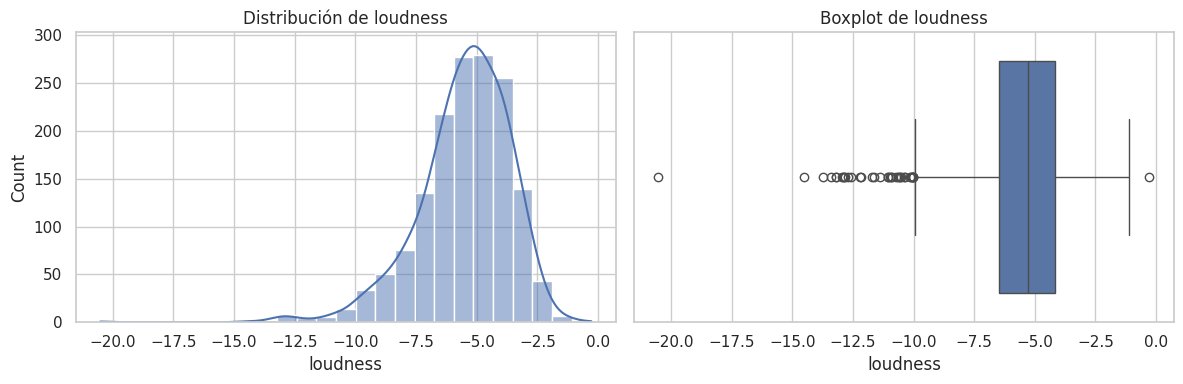


Correlación de las candidatas con loudness:


,Correlación
energy,0.660849
valence,0.244973
liveness,0.104263
tempo,0.084569
danceability,-0.046301
speechiness,-0.085675
instrumentalness,-0.098770
acousticness,-0.325937



Valores nulos en las candidatas:
energy              0
danceability        0
acousticness        0
instrumentalness    0
liveness            0
speechiness         0
tempo               0
valence             0
dtype: int64


In [12]:
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns

# Separar los datos después de eliminar duplicados
spotify_train, spotify_test = train_test_split(
    spotify_limpio,
    test_size=0.20,
    random_state=42
)

candidatas_spotify = [
    "energy",
    "danceability",
    "acousticness",
    "instrumentalness",
    "liveness",
    "speechiness",
    "tempo",
    "valence"
]

print("Filas de entrenamiento:", len(spotify_train))
print("Filas de prueba:", len(spotify_test))

# Revisar el objetivo únicamente en entrenamiento
print("\nResumen de loudness:")
display(spotify_train["loudness"].describe())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(
    data=spotify_train,
    x="loudness",
    bins=25,
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Distribución de loudness")

sns.boxplot(
    data=spotify_train,
    x="loudness",
    ax=axes[1]
)
axes[1].set_title("Boxplot de loudness")

plt.tight_layout()
plt.show()

# Correlaciones calculadas solo con entrenamiento
correlaciones_spotify = (
    spotify_train[candidatas_spotify + ["loudness"]]
    .corr()["loudness"]
    .drop("loudness")
    .sort_values(ascending=False)
)

print("\nCorrelación de las candidatas con loudness:")
display(correlaciones_spotify.to_frame("Correlación"))

print("\nValores nulos en las candidatas:")
print(spotify_train[candidatas_spotify].isna().sum())

Correlación con loudness:


,Correlación
energy,0.660849
valence,0.244973
liveness,0.104263
tempo,0.084569
danceability,-0.046301
speechiness,-0.085675
instrumentalness,-0.098770
acousticness,-0.325937


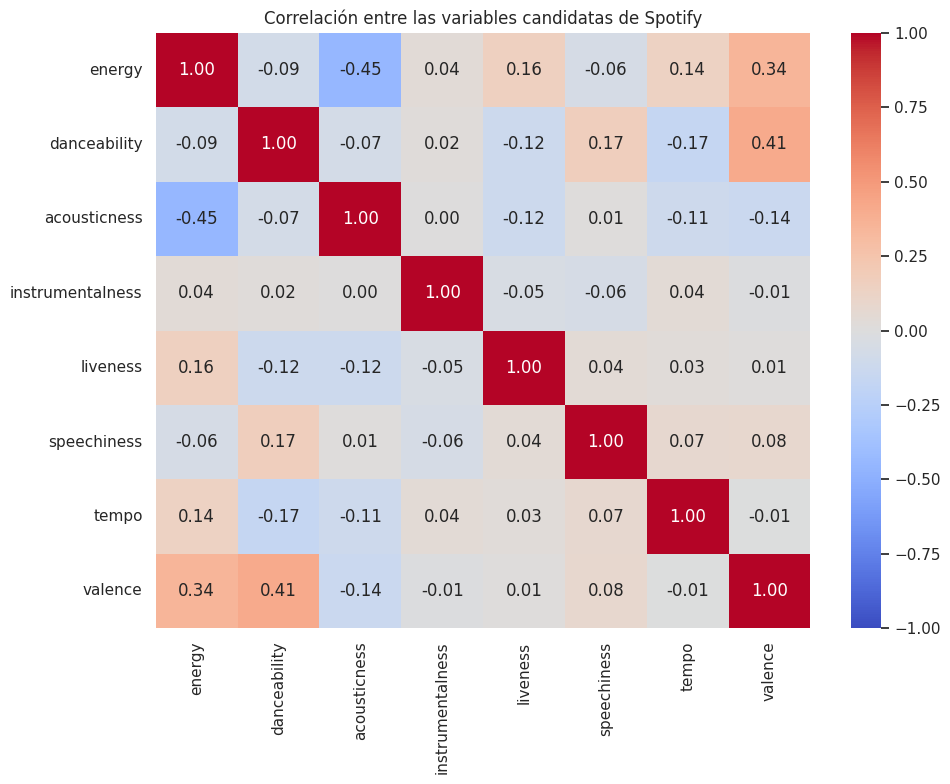

,Variable,VIF
0,energy,1.572
7,valence,1.475
1,danceability,1.409
2,acousticness,1.305
6,tempo,1.069
5,speechiness,1.053
4,liveness,1.051
3,instrumentalness,1.013


In [13]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

X_train_spotify_candidatas = (
    spotify_train[candidatas_spotify].copy()
)

# Mostrar nuevamente la correlación con el objetivo
print("Correlación con loudness:")
display(correlaciones_spotify.to_frame("Correlación"))

# Matriz de correlación entre predictores
plt.figure(figsize=(10, 8))
sns.heatmap(
    X_train_spotify_candidatas.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)
plt.title("Correlación entre las variables candidatas de Spotify")
plt.tight_layout()
plt.show()

# Calcular VIF incluyendo intercepto
X_spotify_constante = sm.add_constant(
    X_train_spotify_candidatas
)

vif_spotify = pd.DataFrame({
    "Variable": candidatas_spotify,
    "VIF": [
        variance_inflation_factor(
            X_spotify_constante.to_numpy(),
            X_spotify_constante.columns.get_loc(variable)
        )
        for variable in candidatas_spotify
    ]
}).sort_values("VIF", ascending=False)

display(vif_spotify.round(3))

In [14]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

# Conservar las ocho candidatas
predictoras_spotify = candidatas_spotify.copy()

X_train_spotify = spotify_train[predictoras_spotify].copy()
X_test_spotify = spotify_test[predictoras_spotify].copy()

y_train_spotify = spotify_train["loudness"]
y_test_spotify = spotify_test["loudness"]

# Entrenar únicamente con entrenamiento
modelo_spotify = LinearRegression()
modelo_spotify.fit(X_train_spotify, y_train_spotify)

pred_train_spotify = modelo_spotify.predict(X_train_spotify)
pred_test_spotify = modelo_spotify.predict(X_test_spotify)

# Comparar métricas
resultados_spotify = []

for nombre, reales, predichos in [
    ("Entrenamiento", y_train_spotify, pred_train_spotify),
    ("Prueba", y_test_spotify, pred_test_spotify)
]:
    resultados_spotify.append({
        "Conjunto": nombre,
        "R²": r2_score(reales, predichos),
        "MAE": mean_absolute_error(reales, predichos),
        "RMSE": np.sqrt(mean_squared_error(reales, predichos))
    })

display(pd.DataFrame(resultados_spotify).round(4))

# Coeficientes del modelo
coeficientes_spotify = pd.DataFrame({
    "Variable": predictoras_spotify,
    "Coeficiente": modelo_spotify.coef_
})

print("\nCoeficientes:")
display(coeficientes_spotify.round(4))

print("Intercepto:", round(modelo_spotify.intercept_, 4))

,Conjunto,R²,MAE,RMSE
0,Entrenamiento,0.4563,1.0832,1.4180
1,Prueba,0.4067,1.1465,1.5397



Coeficientes:


,Variable,Coeficiente
0,energy,8.0760
1,danceability,0.1708
2,acousticness,-0.3401
3,instrumentalness,-2.6498
4,liveness,-0.0181
5,speechiness,-1.1994
6,tempo,0.0002
7,valence,0.1546


Intercepto: -11.3341


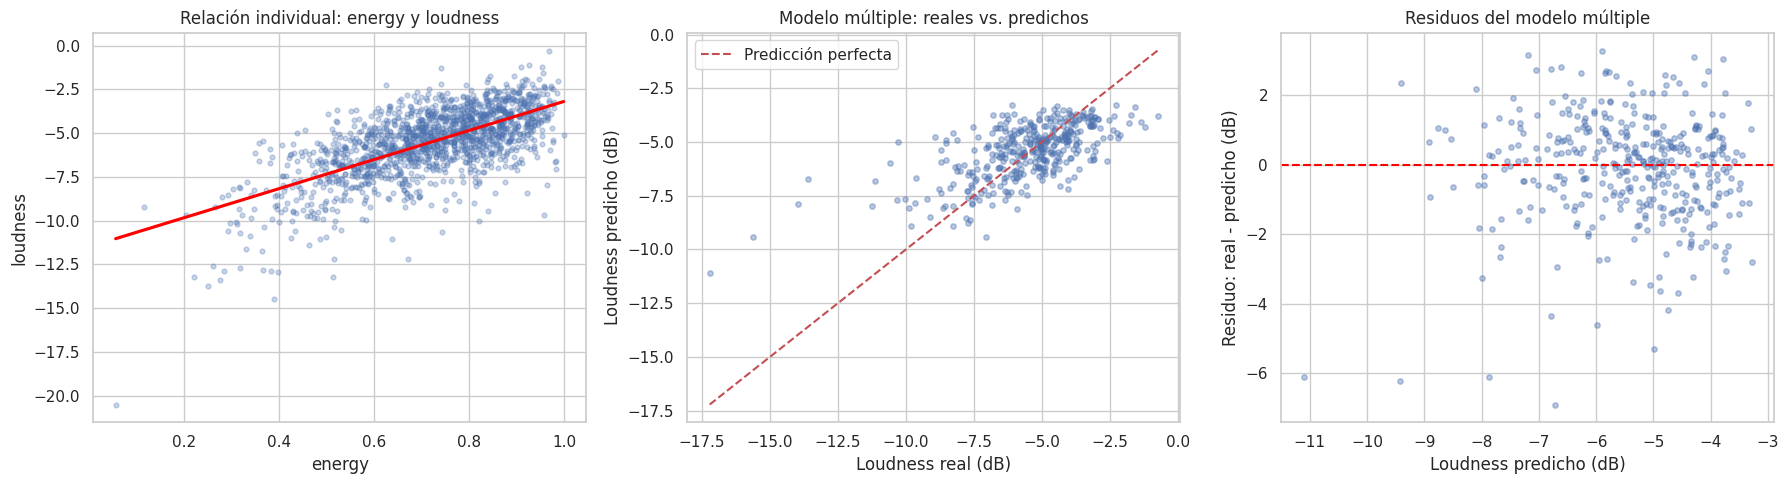

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Relación individual entre energy y loudness
sns.regplot(
    data=spotify_train,
    x="energy",
    y="loudness",
    ci=None,
    scatter_kws={"alpha": 0.3, "s": 12},
    line_kws={"color": "red"},
    ax=axes[0]
)
axes[0].set_title("Relación individual: energy y loudness")

# Valores reales frente a predicciones del modelo múltiple
axes[1].scatter(
    y_test_spotify,
    pred_test_spotify,
    alpha=0.4,
    s=15
)

limite_min = min(y_test_spotify.min(), pred_test_spotify.min())
limite_max = max(y_test_spotify.max(), pred_test_spotify.max())

axes[1].plot(
    [limite_min, limite_max],
    [limite_min, limite_max],
    "r--",
    label="Predicción perfecta"
)
axes[1].set_xlabel("Loudness real (dB)")
axes[1].set_ylabel("Loudness predicho (dB)")
axes[1].set_title("Modelo múltiple: reales vs. predichos")
axes[1].legend()

# Residuos de prueba
residuos_spotify = y_test_spotify - pred_test_spotify

axes[2].scatter(
    pred_test_spotify,
    residuos_spotify,
    alpha=0.4,
    s=15
)
axes[2].axhline(0, color="red", linestyle="--")
axes[2].set_xlabel("Loudness predicho (dB)")
axes[2].set_ylabel("Residuo: real - predicho (dB)")
axes[2].set_title("Residuos del modelo múltiple")

plt.tight_layout()
plt.show()

Mediana de energy en entrenamiento: 0.736


,Grupo,Canciones,R²,MAE,RMSE,Residuo promedio
0,Mayor energía,204,0.1172,1.0857,1.4346,-0.2550
1,Menor energía,185,0.3813,1.2134,1.6477,0.0856


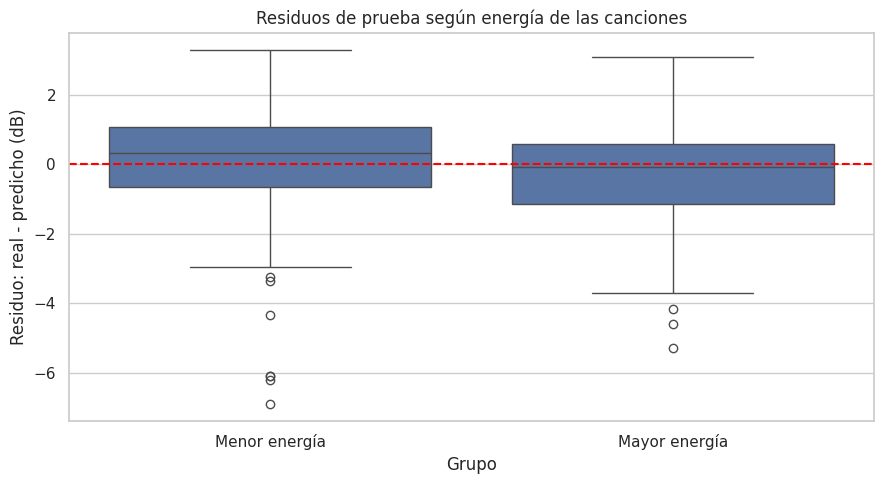

In [16]:
# Definir el límite usando solo entrenamiento
umbral_energia = spotify_train["energy"].median()
print("Mediana de energy en entrenamiento:", umbral_energia)

# Reunir resultados de prueba
evaluacion_spotify = spotify_test[["loudness", "energy"]].copy()
evaluacion_spotify["Prediccion"] = pred_test_spotify
evaluacion_spotify["Residuo"] = (
    evaluacion_spotify["loudness"]
    - evaluacion_spotify["Prediccion"]
)

evaluacion_spotify["Grupo"] = np.where(
    evaluacion_spotify["energy"] <= umbral_energia,
    "Menor energía",
    "Mayor energía"
)

# Calcular métricas por grupo
resultados_grupos_spotify = []

for grupo, datos in evaluacion_spotify.groupby("Grupo"):
    resultados_grupos_spotify.append({
        "Grupo": grupo,
        "Canciones": len(datos),
        "R²": (
            r2_score(datos["loudness"], datos["Prediccion"])
            if len(datos) >= 2 and datos["loudness"].nunique() > 1
            else np.nan
        ),
        "MAE": mean_absolute_error(
            datos["loudness"], datos["Prediccion"]
        ),
        "RMSE": np.sqrt(mean_squared_error(
            datos["loudness"], datos["Prediccion"]
        )),
        "Residuo promedio": datos["Residuo"].mean()
    })

tabla_grupos_spotify = pd.DataFrame(resultados_grupos_spotify)
display(tabla_grupos_spotify.round(4))

# Comparar residuos
plt.figure(figsize=(9, 5))
sns.boxplot(
    data=evaluacion_spotify,
    x="Grupo",
    y="Residuo",
    order=["Menor energía", "Mayor energía"]
)
plt.axhline(0, color="red", linestyle="--")
plt.title("Residuos de prueba según energía de las canciones")
plt.xlabel("Grupo")
plt.ylabel("Residuo: real - predicho (dB)")
plt.tight_layout()
plt.show()

### Preparación y selección de variables

Se utilizó el dataset de Spotify del Laboratorio 01 para estimar loudness, expresado en decibelios, a partir de características musicales.

Se eliminaron 59 filas completamente duplicadas y quedaron 1.941 registros. Luego se separaron 1.552 canciones para entrenamiento y 389 para prueba.

Las ocho variables seleccionadas fueron energy, danceability, acousticness, instrumentalness, liveness, speechiness, tempo y valence. Ninguna presentó valores nulos.

Energy tuvo la mayor correlación con loudness, con un valor aproximado de 0,661. Las correlaciones y el VIF se calcularon únicamente con entrenamiento. Los VIF estuvieron entre 1,013 y 1,572, por lo que se conservaron las ocho variables.

### Resultados e interpretación

La regresión obtuvo un R² de 0,4563 en entrenamiento y de 0,4067 en prueba. Esto significa que explicó aproximadamente el 40,67 % de la variación de loudness en prueba.

El MAE de prueba fue de 1,1465 dB y el RMSE de 1,5397 dB. El modelo captó parte de la tendencia general, pero presentó errores importantes en algunas canciones.

Manteniendo las demás variables constantes, un aumento de 0,1 en energy se asoció con un incremento estimado de 0,8076 dB en loudness. Esta relación describe el modelo y no demuestra causalidad.

Los gráficos mostraron que algunas canciones con niveles sonoros muy bajos fueron sobreestimadas. También aparecieron residuos negativos grandes, lo que indica que el modelo no representa igualmente bien todos los casos.

### Comparación entre grupos

Se dividieron las canciones usando la mediana de energy del entrenamiento, que fue 0,736. Las canciones con energy menor o igual a ese valor quedaron en el grupo de menor energía.

En prueba, las 185 canciones de menor energía tuvieron un MAE de 1,2134 dB y un RMSE de 1,6477 dB. Las 204 canciones de mayor energía tuvieron un MAE de 1,0857 dB y un RMSE de 1,4346 dB.

El residuo promedio fue de 0,0856 dB para menor energía y de −0,2550 dB para mayor energía. Esto muestra una ligera subestimación promedio en el primer grupo y una ligera sobreestimación en el segundo.

Aunque el grupo de mayor energía tuvo menor R², sus errores MAE y RMSE fueron menores. El R² depende de la variación del objetivo dentro de cada grupo, por lo que no debe usarse solo para comparar su desempeño.

### Conclusión

El modelo permitió estimar parcialmente el nivel sonoro de las canciones, pero dejó una parte importante de su variación sin explicar.

La comparación por energía mostró diferencias descriptivas en los errores, con resultados algo mejores en las canciones de mayor energía. Estas diferencias no constituyen por sí solas una prueba estadística.

Por eso, además de revisar el R² general, fue necesario analizar los residuos y los errores por grupo para reconocer las limitaciones del modelo.